In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 4.6 MB/s  0:00:02a 0:00:010:00:0101m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 2.5 MB/s  0:00:02m 2.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.7 MB/s  0:00:024.6 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 5.1 MB/s  0:00:015.3 MB/s eta 0:00:01:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.8 MB/s  0:00:01m 2.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.8 MB/s  0:00:01m 3.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 4.3 MB/s  0:00:04m 4.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [seaborn]━ 14/16 [matplotlib]it-learn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may 

In [2]:
import pandas as pd 

In [3]:
df = pd.read_csv("Food_Delivery_Time_Prediction.csv")

In [4]:
df.head()

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [5]:
df.isnull().sum()

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64

conclusion - no missing values 

In [6]:
from sklearn.preprocessing import OneHotEncoder 
encoder = OneHotEncoder(sparse_output=False)
enc = encoder.fit_transform(df[['Weather_Conditions','Traffic_Conditions','Vehicle_Type']])

In [7]:
from sklearn.preprocessing import StandardScaler 

In [8]:
scaler = StandardScaler()

In [9]:
numerical_columns = ['Distance','Order_Cost']

In [10]:
df[numerical_columns] = scaler.fit_transform(df[numerical_columns])

In [11]:
df.describe()

,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
count,2.000000e+02,200.000000,200.000000,200.000000,200.000000,2.000000e+02,200.000000
mean,-1.643130e-16,5.250000,3.738500,3.686500,70.494950,-2.042810e-16,46.616650
std,1.002509e+00,2.745027,0.703021,0.697063,29.830694,1.002509e+00,29.361706
min,-1.608593e+00,1.000000,2.500000,2.600000,15.230000,-1.688954e+00,1.240000
25%,-7.924313e-01,3.000000,3.200000,3.100000,46.997500,-9.013569e-01,21.602500
50%,-1.806765e-01,5.000000,3.800000,3.700000,72.775000,-1.925947e-02,47.530000
75%,7.325599e-01,8.000000,4.300000,4.300000,96.650000,9.076026e-01,70.245000
max,1.963762e+00,10.000000,5.000000,5.000000,119.670000,1.737826e+00,99.740000


In [12]:
import seaborn as sns 
import matplotlib.pyplot as plt 

(array([ 8., 10.,  3.,  6.,  9.,  7.,  5.,  6.,  6.,  6.,  9.,  7., 10.,
        10.,  9., 14.,  6.,  7.,  8.,  9.,  9., 11.,  8., 10.,  7.]),
 array([ 15.23  ,  19.4076,  23.5852,  27.7628,  31.9404,  36.118 ,
         40.2956,  44.4732,  48.6508,  52.8284,  57.006 ,  61.1836,
         65.3612,  69.5388,  73.7164,  77.894 ,  82.0716,  86.2492,
         90.4268,  94.6044,  98.782 , 102.9596, 107.1372, 111.3148,
        115.4924, 119.67  ]),
 <BarContainer object of 25 artists>)

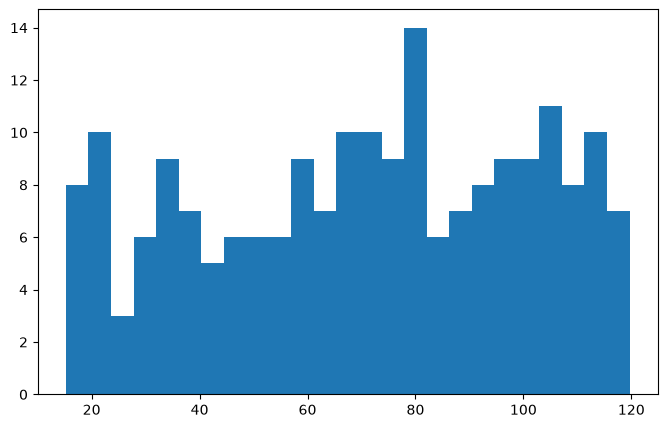

In [13]:
plt.figure(figsize=(8,5))
plt.hist(df['Delivery_Time'],bins = 25)

<Axes: xlabel='Delivery_Time', ylabel='Density'>

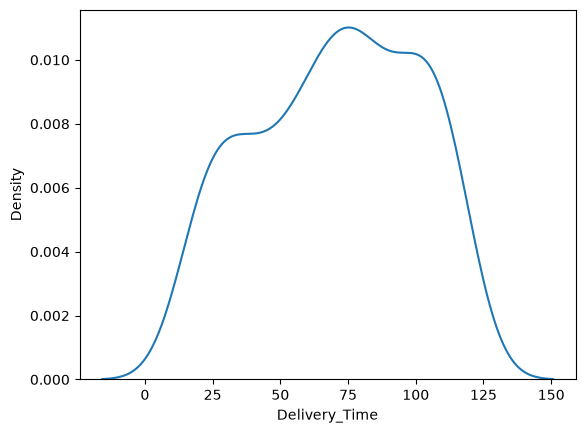

In [14]:
sns.kdeplot(data=df,x='Delivery_Time')

conclusion 
1) Delivery time values are distributed in wide range 
2) kde plot shows that there is no such skewness 

In [15]:
import seaborn as sns 

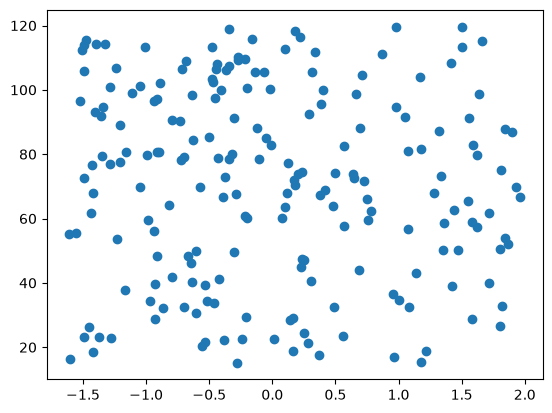

In [16]:
plt.scatter(df['Distance'],df['Delivery_Time'])

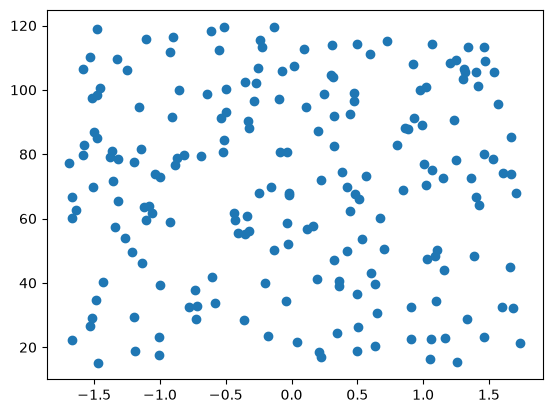

In [17]:
plt.scatter(df['Order_Cost'],df['Delivery_Time'])

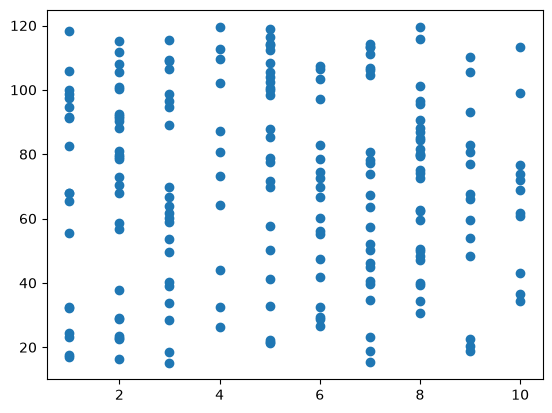

In [18]:
plt.scatter(df['Delivery_Person_Experience'],df['Delivery_Time'])

conclusion 
1)point are scattered across the graph .
2)There is no clear upward or downward pattern .
It means order cost and delivery person experience does not show any linear relationship with delivery time in this scatter plot.

In [19]:
correlation = df[numerical_columns + ['Delivery_Time']].corr()

In [20]:
print(correlation['Delivery_Time'].sort_values(ascending=False))

Delivery_Time    1.000000
Order_Cost      -0.009307
Distance        -0.075143
Name: Delivery_Time, dtype: float64


In [21]:
print(df.columns[df.columns.duplicated()])

Index([], dtype='str')


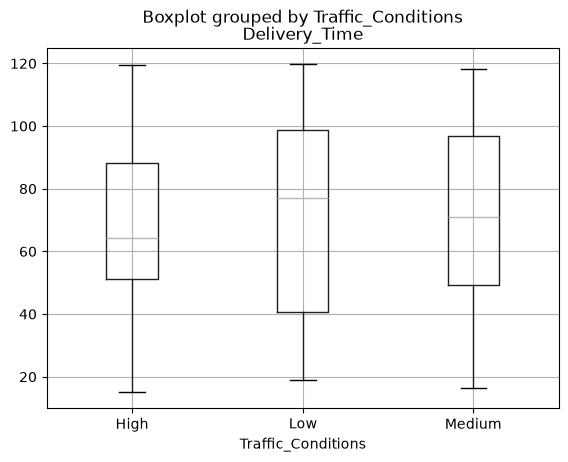

In [22]:
df.boxplot(
    column='Delivery_Time',
    by='Traffic_Conditions'
)
plt.show()

conclusion
low traffic conditions show a higher median delivery time (approximately 77 minutes) compared to high traffic conditions
(approximately 64 minutes).This indicates that traffic conditions alone do not determine delivery time. Other factors, 
such as delivery distance,weather, and restaurant preparation time, may also influence delivery time."


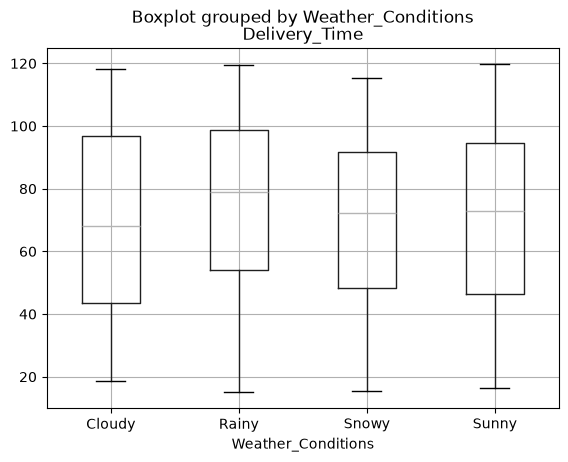

In [23]:
df.boxplot(
    column='Delivery_Time',
    by='Weather_Conditions'
)
plt.show()

In [24]:
df.groupby('Weather_Conditions')['Delivery_Time'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

,mean,median,min,max,count
Weather_Conditions,,,,,
Cloudy,69.786667,68.205,18.67,118.26,42
Rainy,73.058947,79.090,15.23,119.46,57
Snowy,69.191250,72.285,15.42,115.32,48
Sunny,69.479434,72.910,16.48,119.67,53


conclusion 
The results suggest that weather conditions may influence delivery time,
with rainy conditions showing comparatively longer delivery times.

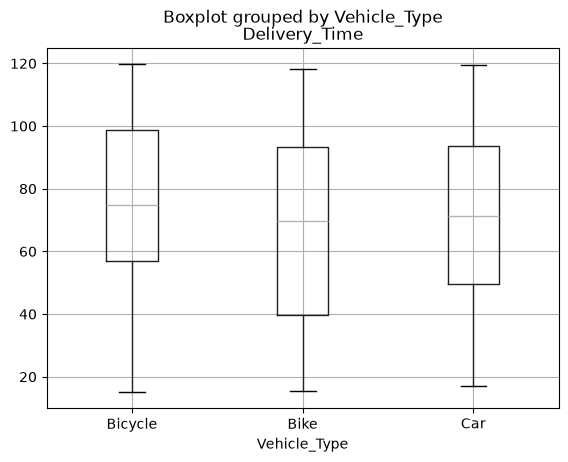

In [25]:
df.boxplot(
    column='Delivery_Time',
    by='Vehicle_Type'
)
plt.show()

In [26]:
df.groupby('Vehicle_Type')['Delivery_Time'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

,mean,median,min,max,count
Vehicle_Type,,,,,
Bicycle,74.315942,74.95,15.23,119.67,69
Bike,66.728696,69.67,15.42,118.26,69
Car,70.434032,71.21,16.98,119.46,62


In [27]:
df.columns

Index(['Order_ID', 'Customer_Location', 'Restaurant_Location', 'Distance',
       'Weather_Conditions', 'Traffic_Conditions',
       'Delivery_Person_Experience', 'Order_Priority', 'Order_Time',
       'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time',
       'Order_Cost', 'Tip_Amount'],
      dtype='str')

In [28]:
df['Order_Time'].value_counts()

Order_Time
Afternoon    59
Evening      57
Night        45
Morning      39
Name: count, dtype: int64

In [29]:
df.groupby('Order_Time')['Delivery_Time'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

,mean,median,min,max,count
Order_Time,,,,,
Afternoon,70.787627,76.57,18.67,119.67,59
Evening,70.305439,71.98,20.29,118.80,57
Morning,71.219487,78.58,15.42,119.46,39
Night,69.723333,67.91,15.23,118.26,45


In [30]:
from sklearn.preprocessing import OneHotEncoder 
encoder = OneHotEncoder(sparse_output=False)
enc = encoder.fit_transform(df[['Order_Time']])

In [31]:
df['peak_period']= df['Order_Time'].apply(
    lambda x: 'peak' if x in ['Afternoon','Evening']
    else'Non peak'
)

In [33]:
from sklearn.model_selection import train_test_split

In [53]:
X = df[['Distance','Weather_Conditions','Traffic_Conditions','Delivery_Person_Experience','Order_Time','Vehicle_Type',
    'Restaurant_Rating','Customer_Rating','Order_Cost','Tip_Amount']]

In [54]:
y = df['Delivery_Time']

In [55]:
X_train,X_test,y_train,y_test = train_test_split(X, y , test_size = 0.2, random_state=42)

In [70]:
X = df[['Distance','Traffic_Conditions','Order_Priority']]

In [71]:
y = df['Delivery_Time']

In [72]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [77]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [78]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0.9 , 4.46, 2.67, 1.96, 0.87]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Distance','Traffic_Conditions_Low','Traffic_Conditions_Medium', 'Order_Priority_Low','Order_Priority_Medium']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,66.83
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [79]:
y_pred = model.predict(X_test)

In [80]:
print(y_pred)

[69.87795736 68.28371092 65.16468675 68.44337843 68.6353729  72.81424133
 71.62436888 68.08771164 70.77310752 72.03141657 69.69171956 68.53622009
 70.76503544 71.39450385 74.29492332 70.67795953 67.72947819 71.83342029
 67.08296315 69.89761967 67.35930769 67.36706135 68.28323333 71.88101364
 68.83205745 73.31511498 71.59396202 69.34662907 71.00697737 69.04604896
 68.43838931 71.84531863 70.27191545 71.59130887 68.90212544 71.37599532
 70.69087056 69.03565123 69.93757982 73.8745154 ]


In [82]:
result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

In [83]:
print(result.head(10))

     Actual  Predicted
95    91.22  69.877957
15    50.11  68.283711
30    87.96  65.164687
158   95.64  68.443378
128   16.98  68.635373
115   63.79  72.814241
69    72.91  71.624369
170  114.28  68.087712
174   93.20  70.773108
45    28.39  72.031417


In [84]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [85]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 915.3719745504928


mean square value is 915.3719745504928

In [86]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.010292275231804426


R2 Score value is 0.010292275231804426

Conclusion
how well the model explains the variation in delivery time.
as Around 0: Model performs no better than predicting the mean in terms of squared error.


In [87]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 25.48472806891557


 Now Creating Fast and Delayed categories from Delivery_Time

In [88]:
import numpy as np

threshold = df['Delivery_Time'].median()

df['Delivery_Status'] = np.where(
    df['Delivery_Time'] <= threshold,
    'Fast',
    'Delayed'
)

print(df['Delivery_Status'].value_counts())

Delivery_Status
Fast       100
Delayed    100
Name: count, dtype: int64


In [89]:
X = df[['Distance', 'Traffic_Conditions',
        'Weather_Conditions',
        'Delivery_Person_Experience',
        'Order_Priority']]

y = df['Delivery_Status']

In [90]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [91]:
y = y.map({'Fast': 0, 'Delayed': 1})

In [92]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [93]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [94]:
y_pred = log_model.predict(X_test)

print(y_pred)

[0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 1 1 1 0 1 1 0 1 0 1 0 1 0 0 1 0 1 0 1 1 0 1
 1 0 1]


In [95]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.375
Precision: 0.3684210526315789
Recall: 0.35
F1 Score: 0.358974358974359
Confusion Matrix:
[[ 8 12]
 [13  7]]


In [96]:
comparison = pd.DataFrame({
    'Actual': y_test.map({0: 'Fast', 1: 'Delayed'}),
    'Predicted': pd.Series(y_pred, index=y_test.index).map(
        {0: 'Fast', 1: 'Delayed'}
    )
})

print(comparison.head(10))

      Actual Predicted
57      Fast      Fast
95   Delayed      Fast
193  Delayed   Delayed
194  Delayed      Fast
33      Fast      Fast
19   Delayed      Fast
45      Fast   Delayed
173  Delayed      Fast
135  Delayed      Fast
162     Fast      Fast


Visualisation 
Actual vs Predicted 

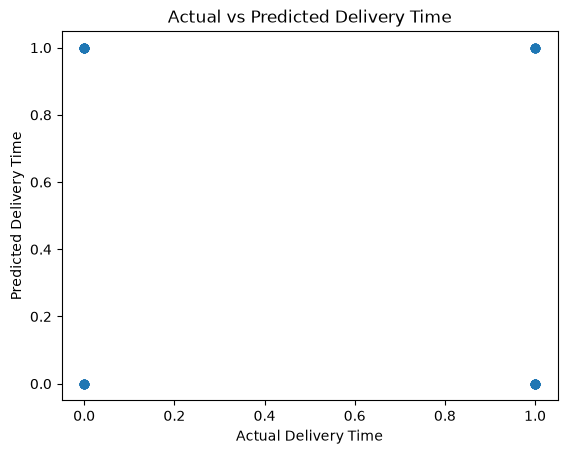

In [97]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")
plt.title("Actual vs Predicted Delivery Time")

plt.show()

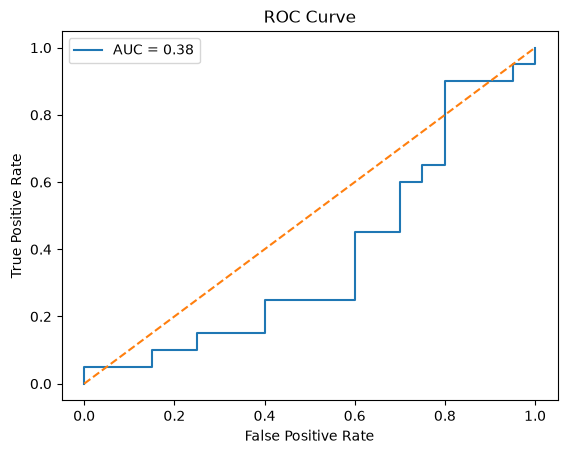

In [98]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = log_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Conclusiion
1)Optimize delivery routes: Use distance and traffic information to identify routes that may cause delays.
2)Adjust staffing: Increase delivery staff availability during high-traffic periods.
3)Improve delivery staff training: Provide training to improve delivery efficiency.
4)Monitor weather conditions: Consider weather when estimating delivery times.